# code_062 · Graph construction and relational meaning

**Book:** section 13.1. A self-contained structure-preserving input laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_13_GUIDE.md), [run evidence](../CHAPTER_13_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_062).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1362;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1362


<a id="relations"></a>
## An edge is a claim about a relationship

Four members form an idealized rectangular frame: two columns, a top beam and a base member. A member graph joins elements that share a connection. Four sensor nodes each observe one member through a directed measurement link; this is a separate relation from mechanical connection. The node positions below are schematic member centroids, not finite-element joints. A declared downward load is attached to the top member. Direction is message flow, not causal identification.

Use A[target,source] so A@x gathers source features at target nodes. Structural connections have two directed entries; measurement links are sensor-to-member only. Equal weights are explicit teaching choices, not calibrated stiffness. Row-normalized neighbor means differ from sums and from adding self-loops. These are construction audits, not a graph-network benchmark.


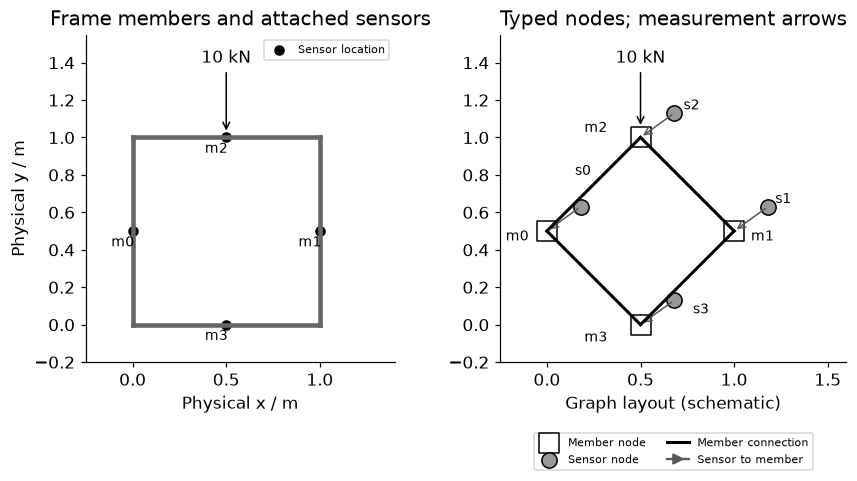

In [2]:
from matplotlib.patches import FancyArrowPatch
member=np.array([[0,.5],[1,.5],[.5,1],[.5,0.]])
sensor=member+np.array([.18,.13]);pos=np.vstack([member,sensor]);ids=[f'm{j}' for j in range(4)]+[f's{j}' for j in range(4)];types=['member']*4+['sensor']*4
physical=[(0,2),(1,2),(0,3),(1,3)];C=np.zeros((8,8));M=np.zeros((8,8))
for a,b in physical:C[a,b]=C[b,a]=1
for j in range(4):M[j,4+j]=1
load=np.zeros((8,2));load[2]=[0,-10] # kN, declared member-level load feature
assert len(set(ids))==8 and not np.diag(C).any() and np.array_equal(C,C.T)
assert M[:4,4:].sum()==4 and M[4:,:].sum()==0
def row_mean(A,x):
 degree=A.sum(axis=1,keepdims=True);return np.divide(A@x,degree,out=np.zeros((len(A),x.shape[1])),where=degree>0)
x=np.arange(1,9,dtype=float)[:,None];connections=row_mean(C,x);measurements=row_mean(M,x);with_self=row_mean(C+np.eye(8),x)
assert not np.allclose(connections,with_self)
perm=np.array([5,2,7,0,6,1,4,3]);np.testing.assert_allclose(row_mean(C[np.ix_(perm,perm)],x[perm]),connections[perm]);np.testing.assert_allclose(row_mean(M[np.ix_(perm,perm)],x[perm]),measurements[perm])
RESULTS['typed_graph']={'nodes':8,'member_nodes':4,'sensor_nodes':4,'structural_directed_entries':int(C.sum()),'measurement_directed_entries':int(M.sum()),'adjacency_convention':'target,source','permutation_equivariance_passed':True,'top_member_load_kN':load[2].tolist()}
fig,axes=plt.subplots(1,2,figsize=(8,4.2));left,ax=axes
frame_segments=[([0,0],[0,1]),([1,0],[1,1]),([0,1],[1,1]),([0,0],[1,0])]
for j,(start,end) in enumerate(frame_segments):
 segment=np.array([start,end]);left.plot(segment[:,0],segment[:,1],lw=3,color='.4');left.annotate(f'm{j}',member[j],xytext=(-14,-10),textcoords='offset points',fontsize=9)
left.scatter(member[:,0],member[:,1],s=35,color='black',label='Sensor location')
left.annotate('10 kN',xy=(.5,1.02),xytext=(.5,1.4),ha='center',arrowprops=dict(arrowstyle='->',color='black'));left.set(xlim=(-.25,1.4),ylim=(-.2,1.55),aspect='equal',xlabel='Physical x / m',ylabel='Physical y / m',title='Frame members and attached sensors');left.legend(fontsize=7,loc='upper right')
for a,b in physical:ax.plot(member[[a,b],0],member[[a,b],1],color='black',lw=2)
ax.scatter(member[:,0],member[:,1],s=170,marker='s',facecolors='white',edgecolors='black',label='Member node');ax.scatter(sensor[:,0],sensor[:,1],s=100,marker='o',color='.6',edgecolors='black',label='Sensor node')
for j in range(4):
 ax.add_patch(FancyArrowPatch(sensor[j],member[j],arrowstyle='->',mutation_scale=12,color='.35'))
 label_member=[(-.22,.45),(1.09,.45),(.20,1.03),(.20,-.09)][j];label_sensor=[(.15,.8),(1.22,.65),(.73,1.15),(.78,.06)][j]
 ax.text(*label_member,ids[j],fontsize=9);ax.text(*label_sensor,ids[4+j],fontsize=9)
ax.plot([],[],color='black',lw=2,label='Member connection');ax.plot([],[],color='.35',marker='>',label='Sensor to member');ax.annotate('10 kN',xy=(.5,1.05),xytext=(.5,1.4),ha='center',arrowprops=dict(arrowstyle='->',color='black'));ax.set(xlim=(-.25,1.6),ylim=(-.2,1.55),aspect='equal',xlabel='Graph layout (schematic)',ylabel='',title='Typed nodes; measurement arrows');ax.legend(fontsize=7,loc='upper center',bbox_to_anchor=(.5,-.2),ncol=2);plt.show()


<a id="similarity"></a>
## Fit a similarity graph only on admitted history

Generate 120 simultaneous observations at the four sensors. The first 80 training observations have two strongly correlated sensor pairs; the final 40 receive a strong shared component. A graph connects sensor pairs with absolute Pearson correlation above .8, fitted only on the first 80 inputs. Reusing all 120 observations changes the graph using future inputs. Neither graph establishes mechanical connectivity or causation. A learned graph would add fitted parameters/objective and must respect the same evidence boundary; no learned graph estimator is trained here.


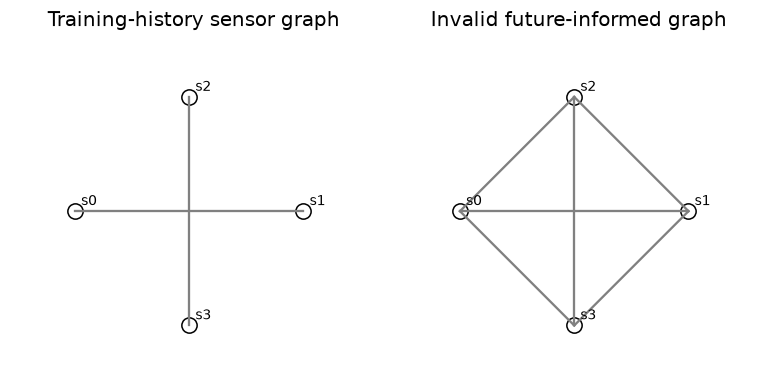

In [3]:
t=np.arange(120);f=np.sin(.23*t);g=np.cos(.37*t);signals=np.column_stack([f,f,g,g])+rng.normal(0,.05,(120,4));signals[80:]+=5*np.sin(.41*t[80:])[:,None]
def correlation_graph(A):
 corr=np.corrcoef(A,rowvar=False);edges=np.abs(corr)>.8;np.fill_diagonal(edges,False);return corr,edges
corr,safe=correlation_graph(signals[:80]);_,invalid=correlation_graph(signals);assert not np.array_equal(safe,invalid)
# Modifying future inputs cannot affect the training-only graph.
changed=signals.copy();changed[80:]*=100;np.testing.assert_array_equal(correlation_graph(changed[:80])[1],safe)
RESULTS['correlation_graph']={'threshold':.8,'fit_observations':80,'training_undirected_edges':int(safe.sum()/2),'invalid_all_history_edges':int(invalid.sum()/2),'construction_uses_no_targets':True}
fig,axes=plt.subplots(1,2,figsize=(7,3.4))
for ax,A,title in zip(axes,[safe,invalid],['Training-history sensor graph','Invalid future-informed graph']):
 for i in range(4):
  for j in range(i):
   if A[i,j]:ax.plot(sensor[[i,j],0],sensor[[i,j],1],color='.5')
 ax.scatter(sensor[:,0],sensor[:,1],s=100,color='white',edgecolors='black')
 for j in range(4):ax.annotate(f's{j}',sensor[j],xytext=(4,4),textcoords='offset points',fontsize=9)
 ax.set(title=title,aspect='equal',xlim=(-.1,1.5),ylim=(-.1,1.4));ax.axis('off')
plt.show()


In [4]:
summary={'example_id':'code_062','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['physical member and sensor node types', 'directed typed relations and self-loops', 'training-only correlation graph', 'stable identifiers and permutation equivariance'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["physical member and sensor node types", "directed typed relations and self-loops", "training-only correlation graph", "stable identifiers and permutation equivariance"], "elapsed_seconds": 0.172, "example_id": "code_062", "hardware": "Darwin arm64 CPU", "results": {"correlation_graph": {"construction_uses_no_targets": true, "fit_observations": 80, "invalid_all_history_edges": 6, "threshold": 0.8, "training_undirected_edges": 2}, "typed_graph": {"adjacency_convention": "target,source", "measurement_directed_entries": 4, "member_nodes": 4, "nodes": 8, "permutation_equivariance_passed": true, "sensor_nodes": 4, "structural_directed_entries": 8, "top_member_load_kN": [0.0, -10.0]}}, "seed": 1362, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
